# Rough-set boundary regions: which stressed answers are not decided?

A stressed risk figure is only useful for a decision (flag, stage, review, reprice) when it falls clearly on one side of a threshold. A loan whose stressed lifetime default probability is 6.1% against a 6% threshold is "high" under the scenario as written and "low" if the house-price fall comes a few months later or a little milder. A single number and a single label hide that.

This notebook shows the **rough-set three-way decision** that the platform lays over the LightGBM survival model's stressed output. For a loan and a threshold, the stress is varied within a small neighbourhood and every variant is projected. Then:

| Region | Meaning (rough-set term) | Rule, with `k` of `n` variants at or above the threshold |
|---|---|---|
| ▲ **Certain high** | lower approximation of "high": high under every variant | `k/n >= 1 - β` |
| ◆ **Boundary** | upper minus lower approximation: the answer depends on the details of the stress | otherwise |
| ▼ **Certain low** | outside the upper approximation: high under no variant | `k/n <= β` |

`β` is a variable-precision tolerance (default 0, the strict Pawlak approximation). The boundary loans are the ones to send to an analyst.

**What this is not.** It is a robustness classification, not a probability, and it has no coverage guarantee. How wide the boundary is depends on the neighbourhood chosen (the `band` and `timing` below), which is a modelling choice, not a measured quantity. See the last section and `MODELS.md`.

**How the notebook runs.** It uses two independent Python implementations that already live in the repo and that the Java service is held to by golden tests: `backend/golden_term_structure.py` (the whole term-structure projection, running the shipped ONNX survival model) and `backend/golden_rough_set.py` (the variant generator and the rule). No service, database or raw data is needed. Needs `numpy pandas matplotlib onnxruntime`. Running every cell projects about 4,100 loans-under-a-scenario in Python, which takes five to ten minutes; the portfolio section is most of that.

## 1. Setup and a check that this is the same code the service is tested against

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd() if (Path.cwd() / "backend").exists() else Path.cwd().parent
sys.path.insert(0, str(REPO / "backend"))
import golden_term_structure as gt   # independent Python implementation of the term-structure engine
import golden_rough_set as gr        # independent Python implementation of the region layer

gt.RESOURCES = REPO / "backend/risk-engine/src/main/resources"
engine = gt.Artifacts()
print("survival model:", engine.meta["version"])

# Colours are the console's risk spectrum; a region is never shown by colour alone (glyph + words go with it).
INK, MUTED, GRID = "#1d1d1b", "#6b6a66", "#e4e2dc"
REGION = {
    "CERTAIN_HIGH": ("#d64545", "▲", "High under every variant"),
    "BOUNDARY": ("#e0a526", "◆", "Depends on the stress details"),
    "CERTAIN_LOW": ("#2f9e6b", "▼", "Low under every variant"),
}
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
SCENARIOS = {"BASELINE": gt.BASELINE, "ADVERSE": gt.ADVERSE, "SEVERELY_ADVERSE": gt.SEVERELY_ADVERSE}

survival model: 2026.10.07-0525


In [2]:
# 1. The checked-in fixture that the Java RoughSetGoldenTest holds the service to is exactly what this Python
#    reference produces today, so what follows is what the service computes.
golden = json.loads((REPO / "backend/risk-engine/src/test/resources/rough_set_golden.json").read_text(encoding="utf-8"))
same_members = all(
    [gr.variant(c["target"], i, c["shockBand"], c["timingBandMonths"], c["seed"]) for i in range(1, 9)] == c["members"]
    for c in golden["generator"]
)
same_rule = all(gr.classify(c["metrics"], c["threshold"], c["tolerance"]) == c["expected"] for c in golden["classifier"])
print(f"variant generator: {len(golden['generator'])} cases identical to the fixture -> {same_members}")
print(f"three-way rule:    {len(golden['classifier'])} cases identical to the fixture -> {same_rule}")

# 2. The Python projection reproduces the term-structure golden file the Java engine is held to (1e-6).
ts = json.loads((REPO / "backend/risk-engine/src/test/resources/term_structure_golden.json").read_text(encoding="utf-8"))
case = next(c for c in ts["cases"] if c["request"]["loan"]["loanId"] == "prime" and c["request"]["scenario"]["name"] == "SEVERELY_ADVERSE")
mine = gt.project(engine, dict(loan=gt.PRIME, scenario=gt.SEVERELY_ADVERSE))
print(f"prime / severely adverse lifetime PD: python {mine['pdLifetime']:.6f}, golden file {case['expected']['pdLifetime']:.6f}")

variant generator: 224 cases identical to the fixture -> True
three-way rule:    404 cases identical to the fixture -> True
prime / severely adverse lifetime PD: python 0.060875, golden file 0.060875


## 2. One loan: the variants, and where the boundary sits

A **granule** is the set of variants of the scenario being decided. Member 0 is the scenario as written. Every other member scales the unemployment, house-price and rate shocks by a factor in `1 ± band` and moves their timing by up to `±timing` months (clamped to what a scenario allows; a parameter that is zero stays zero, so a baseline has nothing to perturb). Each variant is a pure function of `(seed, index)` (splitmix64), so the same request gives the same variants on any number of threads.

The default neighbourhood is **±20% on shock sizes and ±3 months on timing**. Section 5 shows what that choice costs and buys.

In [3]:
BAND, TIMING, N = 0.20, 3, 32      # the service defaults for a single loan: band 20%, timing 3 months, 32 variants


def variants(target, n=N, band=BAND, timing=TIMING, seed=17):
    # member 0 is the target; the rest are its seeded neighbourhood
    return [target] + [gr.variant(target, i, band, timing, seed) for i in range(1, n)]


def figures(loan, scenario):
    r = gt.project(engine, dict(loan=loan, scenario=scenario))
    return dict(pd12m=r["pd12m"], pdLifetime=r["pdLifetime"], ecl=r["eclLifetime"], exposure=r["exposure"])


def granule(loan, target, **kw):
    t0 = time.time()
    out = pd.DataFrame([figures(loan, s) for s in variants(target, **kw)])
    return out, time.time() - t0


loan, target = gt.PRIME, gt.SEVERELY_ADVERSE
g, seconds = granule(loan, target)
print(f"{len(g)} variants of SEVERELY_ADVERSE projected in {seconds:.1f} s")
g.head(6).assign(pd12m=g.pd12m.map("{:.3%}".format), pdLifetime=g.pdLifetime.map("{:.3%}".format),
                 ecl=g.ecl.map("${:,.0f}".format), exposure=g.exposure.map("${:,.0f}".format))

32 variants of SEVERELY_ADVERSE projected in 4.7 s


,pd12m,pdLifetime,ecl,exposure
0,1.600%,6.088%,$561,"$350,000"
1,1.713%,7.168%,"$1,137","$350,000"
2,1.854%,5.693%,$361,"$350,000"
3,1.391%,6.110%,$632,"$350,000"
4,2.110%,7.086%,$842,"$350,000"
5,1.449%,4.805%,$209,"$350,000"


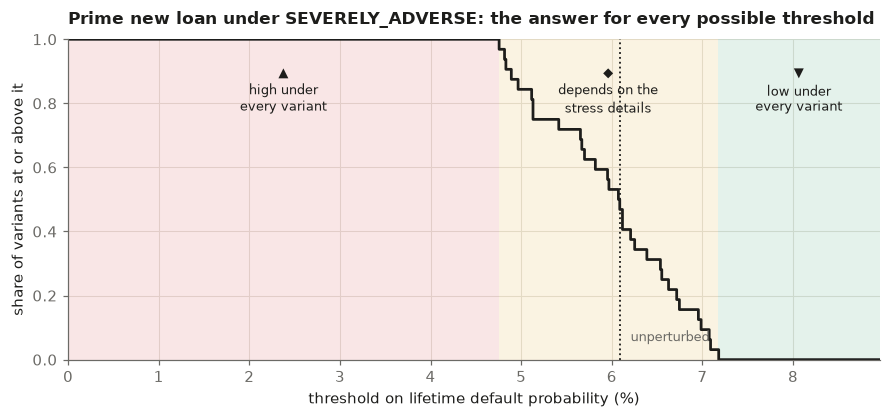

Across 32 variants the lifetime PD runs from 4.75% to 7.17% (unperturbed 6.09%).
A threshold below 4.75% puts this loan in the lower approximation (high under every variant); above 7.17% it is outside the upper
approximation; anywhere in between it is on the boundary. The boundary is the interval of thresholds that the details of the stress can flip.


In [4]:
def ribbon(ax, values, base, label, unit="lifetime default probability"):
    lo, hi = values.min(), values.max()
    xs = np.linspace(0, hi * 1.25, 600)
    share = np.array([(values >= x).mean() for x in xs])
    for (a, b, region) in ((0, lo, "CERTAIN_HIGH"), (lo, hi, "BOUNDARY"), (hi, xs[-1], "CERTAIN_LOW")):
        colour, glyph, words = REGION[region]
        ax.axvspan(a * 100, b * 100, color=colour, alpha=0.13, lw=0)
        short = {"CERTAIN_HIGH": "high under\nevery variant", "BOUNDARY": "depends on the\nstress details", "CERTAIN_LOW": "low under\nevery variant"}[region]
        ax.text((a + b) / 2 * 100, 0.92, f"{glyph}\n{short}", ha="center", va="top", fontsize=8.5, color=INK, linespacing=1.3)
    ax.step(xs * 100, share, where="post", color=INK, lw=1.8)
    ax.axvline(base * 100, color=INK, ls=":", lw=1.2)
    ax.annotate("unperturbed", (base * 100, 0.07), xytext=(base * 100 + 0.12, 0.07), fontsize=8.5, color=MUTED, va="center")
    ax.set_xlim(0, xs[-1] * 100)
    ax.set_ylim(0, 1.0)
    ax.set_xlabel(f"threshold on {unit} (%)")
    ax.set_ylabel("share of variants at or above it")
    ax.set_title(label, pad=10)


fig, ax = plt.subplots(figsize=(8.2, 3.9))
ribbon(ax, g["pdLifetime"].to_numpy(), g.loc[0, "pdLifetime"], "Prime new loan under SEVERELY_ADVERSE: the answer for every possible threshold")
fig.tight_layout()
plt.show()

lo, hi = g["pdLifetime"].min(), g["pdLifetime"].max()
print(f"Across {N} variants the lifetime PD runs from {lo:.2%} to {hi:.2%} (unperturbed {g.loc[0,'pdLifetime']:.2%}).")
print(f"A threshold below {lo:.2%} puts this loan in the lower approximation (high under every variant); above {hi:.2%} it is outside the upper")
print("approximation; anywhere in between it is on the boundary. The boundary is the interval of thresholds that the details of the stress can flip.")

In [5]:
# The same loan at three thresholds, with the strict rule and with a 10% allowance for exceptions
rows = []
for threshold in (0.04, g.loc[0, "pdLifetime"], 0.08):
    for tolerance in (0.0, 0.10):
        c = gr.classify(g["pdLifetime"].tolist(), threshold, tolerance)
        rows.append(dict(threshold=f"{threshold:.2%}", tolerance=f"{tolerance:.0%}", high=f"{c['high']} of {c['members']}",
                         region=f"{REGION[c['region']][1]} {REGION[c['region']][2]}", width=f"{c['width']:.2%}"))
pd.DataFrame(rows)

,threshold,tolerance,high,region,width
0,4.00%,0%,32 of 32,▲ High under every variant,2.42%
1,4.00%,10%,32 of 32,▲ High under every variant,2.42%
2,6.09%,0%,16 of 32,◆ Depends on the stress details,2.42%
3,6.09%,10%,16 of 32,◆ Depends on the stress details,2.42%
4,8.00%,0%,0 of 32,▼ Low under every variant,2.42%
5,8.00%,10%,0 of 32,▼ Low under every variant,2.42%


## 3. Several loans, two scenarios

Boundaries differ by loan and by scenario. The bars are the range of the lifetime PD across the 32 variants; the dot is the unperturbed figure; the line is a 5% threshold. The label on the right is the region the loan lands in at that threshold.

320 projections in 43 s


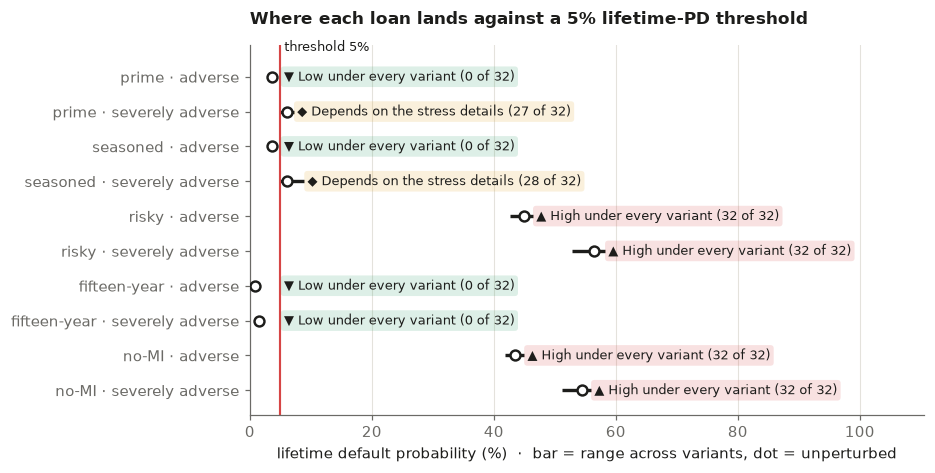

,loan,scenario,base,lo,hi,high,region
0,prime,ADVERSE,3.71%,3.42%,3.95%,0,CERTAIN_LOW
1,prime,SEVERELY_ADVERSE,6.09%,4.75%,7.17%,27,BOUNDARY
2,seasoned,ADVERSE,3.72%,3.52%,4.03%,0,CERTAIN_LOW
3,seasoned,SEVERELY_ADVERSE,6.07%,4.81%,8.86%,28,BOUNDARY
4,risky,ADVERSE,44.89%,42.58%,46.36%,32,CERTAIN_HIGH
5,risky,SEVERELY_ADVERSE,56.36%,52.80%,58.17%,32,CERTAIN_HIGH
6,fifteen-year,ADVERSE,0.82%,0.73%,0.94%,0,CERTAIN_LOW
7,fifteen-year,SEVERELY_ADVERSE,1.56%,1.17%,1.85%,0,CERTAIN_LOW
8,no-MI,ADVERSE,43.49%,41.82%,44.91%,32,CERTAIN_HIGH
9,no-MI,SEVERELY_ADVERSE,54.46%,51.25%,55.88%,32,CERTAIN_HIGH


In [6]:
loans = [("prime", gt.PRIME), ("seasoned", gt.SEASONED), ("risky", gt.RISKY), ("fifteen-year", gt.FIFTEEN), ("no-MI", gt.NO_MI)]
THRESHOLD = 0.05
records = []
t0 = time.time()
for name, ln in loans:
    for sname in ("ADVERSE", "SEVERELY_ADVERSE"):
        gv, _ = granule(ln, SCENARIOS[sname])
        c = gr.classify(gv["pdLifetime"].tolist(), THRESHOLD, 0.0)
        records.append(dict(loan=name, scenario=sname, base=gv.loc[0, "pdLifetime"], lo=c["min"], hi=c["max"], high=c["high"], region=c["region"]))
several = pd.DataFrame(records)
print(f"{len(several) * N} projections in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(8.6, 4.4))
ylabels = []
for i, r in several.iterrows():
    y = len(several) - 1 - i
    colour, glyph, words = REGION[r["region"]]
    ax.hlines(y, r["lo"] * 100, r["hi"] * 100, color=INK, lw=2.2, zorder=2)
    ax.plot(r["base"] * 100, y, "o", ms=6.5, mfc="white", mec=INK, mew=1.6, zorder=3)
    ax.text(max(r["hi"] * 100, THRESHOLD * 100) + 0.6, y, f"{glyph} {words} ({r['high']} of {N})", va="center", fontsize=8.5, color=INK,
            bbox=dict(boxstyle="round,pad=0.25", fc=colour, ec="none", alpha=0.16))
    ylabels.append((y, f"{r['loan']} · {r['scenario'].replace('_', ' ').lower()}"))
ax.axvline(THRESHOLD * 100, color="#d64545", lw=1.4)
ax.text(THRESHOLD * 100, len(several) - 0.35, " threshold 5%", color=INK, fontsize=8.5, va="bottom")
ax.set_yticks([y for y, _ in ylabels], [t for _, t in ylabels])
ax.set_xlabel("lifetime default probability (%)  ·  bar = range across variants, dot = unperturbed")
ax.set_xlim(0, max(several["hi"].max() * 100 * 1.9, 14))
ax.set_ylim(-0.7, len(several) - 0.1)
ax.grid(axis="y", visible=False)
ax.set_title("Where each loan lands against a 5% lifetime-PD threshold", pad=14)
fig.tight_layout()
plt.show()
several.assign(base=several.base.map("{:.2%}".format), lo=several.lo.map("{:.2%}".format), hi=several.hi.map("{:.2%}".format))

## 4. The whole demo portfolio

The service does this for every loan of a portfolio run (`decision` on `POST /risk/portfolio/runs`). Here the same is done for the 400-loan demo catalog under SEVERELY_ADVERSE, with 8 variants per loan, a 5% lifetime-PD threshold and each loan's seed derived from its id (the service derives it from the whole request; the variants therefore differ from a console run, and the counts will be close but not identical to one).

That is 3,200 projections, so it takes a couple of minutes.

In [7]:
catalog = json.loads((gt.RESOURCES / "loan_catalog.json").read_text(encoding="utf-8"))
PN, PTARGET, PTHRESH = 8, gt.SEVERELY_ADVERSE, 0.05
SEED_MASK = (1 << 52) - 1

t0 = time.time()
book = []
for k, ln in enumerate(catalog):
    seed = gr.fnv1a(ln["loanId"]) & SEED_MASK
    gv, _ = granule(ln, PTARGET, n=PN, seed=seed)
    book.append(dict(loanId=ln["loanId"], state=ln["propertyState"], exposure=gv.loc[0, "exposure"], pd=gv["pdLifetime"].to_numpy(),
                     ecl=gv["ecl"].to_numpy()))
    if (k + 1) % 100 == 0:
        print(f"  {k + 1} of {len(catalog)} loans, {time.time() - t0:.0f} s")
print(f"{len(catalog) * PN} projections in {time.time() - t0:.0f} s")

  100 of 400 loans, 101 s


  200 of 400 loans, 208 s


  300 of 400 loans, 309 s


  400 of 400 loans, 411 s
3200 projections in 411 s


In [8]:
def classify_book(threshold, tolerance=0.0):
    out = []
    for b in book:
        c = gr.classify(b["pd"].tolist(), threshold, tolerance)
        out.append(dict(loanId=b["loanId"], state=b["state"], exposure=b["exposure"], region=c["region"], high=c["high"],
                        lo=c["min"], hi=c["max"], base=b["pd"][0], ecl_base=b["ecl"][0], ecl_min=b["ecl"].min(), ecl_max=b["ecl"].max()))
    return pd.DataFrame(out)


res = classify_book(PTHRESH)
split = res.groupby("region").agg(loans=("loanId", "count"), exposure=("exposure", "sum"))
split["share of exposure"] = split["exposure"] / split["exposure"].sum()
split = split.reindex(["CERTAIN_HIGH", "BOUNDARY", "CERTAIN_LOW"])
split.index = [f"{REGION[r][1]} {REGION[r][2]}" for r in split.index]
display(split.assign(exposure=split.exposure.map("${:,.0f}".format), **{"share of exposure": split["share of exposure"].map("{:.1%}".format)}))

lower = res.loc[res.region == "CERTAIN_HIGH", "ecl_min"].sum()
upper = res.loc[res.region != "CERTAIN_LOW", "ecl_max"].sum()
base_high = res.loc[res.base >= PTHRESH, "ecl_base"].sum()
print(f"Lifetime expected loss of the high-risk part of the book: between ${lower:,.0f} and ${upper:,.0f}; ${base_high:,.0f} under the unperturbed scenario.")
print("  lower figure = loans that are high under every variant, each at its lowest; upper adds the boundary loans, each at its highest.")
assert lower <= base_high + 1e-6 <= upper + 2e-6, "with tolerance 0 the unperturbed figure is bracketed"

,loans,exposure,share of exposure
▲ High under every variant,249,"$71,721,934",63.5%
◆ Depends on the stress details,29,"$10,255,441",9.1%
▼ Low under every variant,122,"$30,907,549",27.4%


Lifetime expected loss of the high-risk part of the book: between $110,177 and $231,969; $155,214 under the unperturbed scenario.
  lower figure = loans that are high under every variant, each at its lowest; upper adds the boundary loans, each at its highest.


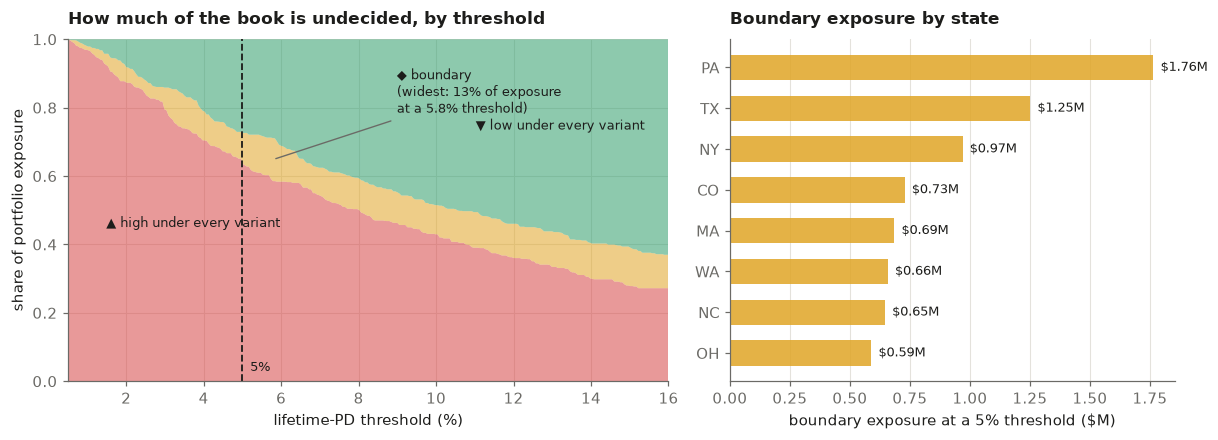

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.2, 4.1), gridspec_kw=dict(width_ratios=[1.35, 1]))

# Left: how the book divides as the threshold moves. With tolerance 0 a loan is on the boundary when min < t <= max.
ts_ = np.linspace(0.005, 0.16, 300)
lo_, hi_, ex_ = res["lo"].to_numpy(), res["hi"].to_numpy(), res["exposure"].to_numpy()
high = np.array([ex_[lo_ >= t].sum() for t in ts_]) / ex_.sum()
low = np.array([ex_[hi_ < t].sum() for t in ts_]) / ex_.sum()
mid = 1 - high - low
a1.stackplot(ts_ * 100, high, mid, low, colors=[REGION["CERTAIN_HIGH"][0], REGION["BOUNDARY"][0], REGION["CERTAIN_LOW"][0]], alpha=0.55, lw=0)
a1.axvline(PTHRESH * 100, color=INK, lw=1.2, ls="--")
a1.text(PTHRESH * 100 + 0.2, 0.03, "5%", fontsize=8.5)
i_hi, i_lo = int(np.argmin(abs(ts_ - 0.015))), int(np.argmin(abs(ts_ - 0.11)))
a1.text(ts_[i_hi] * 100, high[i_hi] / 2, f"{REGION['CERTAIN_HIGH'][1]} high under every variant", fontsize=8.5, va="center")
a1.text(ts_[i_lo] * 100, 1 - low[i_lo] / 2, f"{REGION['CERTAIN_LOW'][1]} low under every variant", fontsize=8.5, va="center")
j = int(np.argmax(mid))
a1.annotate(f"{REGION['BOUNDARY'][1]} boundary\n(widest: {mid[j]:.0%} of exposure\nat a {ts_[j] * 100:.1f}% threshold)", (ts_[j] * 100, high[j] + mid[j] / 2),
            xytext=(ts_[j] * 100 + 3.2, high[j] + 0.2), fontsize=8.5, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.9))
a1.set_xlim(0.5, 16)
a1.set_ylim(0, 1)
a1.set_xlabel("lifetime-PD threshold (%)")
a1.set_ylabel("share of portfolio exposure")
a1.set_title("How much of the book is undecided, by threshold", pad=10)

# Right: where the boundary exposure sits.
bs = res[res.region == "BOUNDARY"].groupby("state")["exposure"].sum().sort_values(ascending=False).head(8)[::-1]
a2.barh(bs.index, bs.values / 1e6, color=REGION["BOUNDARY"][0], alpha=0.85, height=0.62)
for y, v in enumerate(bs.values):
    a2.text(v / 1e6 + 0.03, y, f"${v / 1e6:.2f}M", va="center", fontsize=8.5)
a2.set_xlabel("boundary exposure at a 5% threshold ($M)")
a2.set_title("Boundary exposure by state", pad=10)
a2.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

In [10]:
# The boundary loans to review, largest first
cols = ["loanId", "state", "exposure", "high", "base", "lo", "hi", "ecl_min", "ecl_max"]
review = res[res.region == "BOUNDARY"].sort_values("exposure", ascending=False)[cols].head(10)
review = review.rename(columns={"high": f"variants high (of {PN})", "base": "unperturbed PD", "lo": "lowest PD", "hi": "highest PD",
                                "ecl_min": "loss, low", "ecl_max": "loss, high"})
for col, fmt in (("exposure", "${:,.0f}"), ("unperturbed PD", "{:.2%}"), ("lowest PD", "{:.2%}"), ("highest PD", "{:.2%}"),
                 ("loss, low", "${:,.0f}"), ("loss, high", "${:,.0f}")):
    review[col] = review[col].map(fmt.format)
review.reset_index(drop=True)

,loanId,state,exposure,variants high (of 8),unperturbed PD,lowest PD,highest PD,"loss, low","loss, high"
0,F26Q10075220,CO,"$728,142",7,5.20%,4.72%,5.91%,"$1,196","$2,739"
1,F23Q10016475,WA,"$657,930",7,5.80%,4.97%,6.41%,$186,$264
2,F24Q20247089,NC,"$646,186",4,4.87%,4.10%,7.22%,$352,"$2,055"
3,F24Q10179356,PA,"$619,937",7,5.72%,4.96%,6.67%,$233,$302
4,F22Q40209354,PA,"$513,150",6,5.47%,4.14%,6.12%,$134,$221
5,F24Q30158165,NY,"$500,429",1,4.32%,3.69%,5.15%,$191,$805
6,F25Q20138364,TX,"$480,839",6,5.45%,3.63%,11.16%,$129,$574
7,F22Q30122139,NY,"$468,880",5,5.42%,4.85%,6.37%,$121,$174
8,F24Q40095672,NH,"$432,795",7,5.98%,4.98%,6.59%,$129,$363
9,F25Q10110496,PA,"$424,776",6,5.09%,4.40%,6.57%,$411,"$1,114"


## 5. How much does the neighbourhood matter?

The boundary is only as wide as the neighbourhood you give it. This is the table behind the service's defaults: the half-width of the spread of the figure across 32 variants, as a share of the unperturbed figure, for a range of bands. Read it as "how far the details of the stress can move this number".

Two things to look for. **Timing** barely moves a lifetime figure but moves a 12-month figure a lot (the shock lands inside or outside the first year). And **the same band gives a wider boundary the harsher the scenario**.

In [11]:
rows = []
t0 = time.time()
for sname in ("ADVERSE", "SEVERELY_ADVERSE"):
    for band in (0.10, 0.20, 0.30):
        for timing in (0, 3, 6):
            gv, _ = granule(gt.PRIME, SCENARIOS[sname], band=band, timing=timing)
            for metric, label in (("pd12m", "12-month PD"), ("pdLifetime", "lifetime PD")):
                v = gv[metric]
                rows.append(dict(scenario=sname, figure=label, band=f"±{band:.0%}", timing=f"±{timing} mo", half_width=(v.max() - v.min()) / (2 * v[0])))
print(f"{len(rows) // 2 * N} projections in {time.time() - t0:.0f} s")
sens = pd.DataFrame(rows)
table = sens.pivot_table(index=["scenario", "figure"], columns=["band", "timing"], values="half_width")
table.apply(lambda col: col.map("{:.1%}".format))

576 projections in 89 s


band                           ±10%                 ±20%                 ±30%  \
timing                        ±0 mo  ±3 mo  ±6 mo  ±0 mo  ±3 mo  ±6 mo  ±0 mo   
scenario         figure                                                         
ADVERSE          12-month PD   8.4%  20.7%  33.8%  17.4%  26.7%  38.3%  24.4%   
                 lifetime PD   3.8%   3.8%   4.5%   7.7%   7.1%   7.9%  10.8%   
SEVERELY_ADVERSE 12-month PD  11.1%  34.6%  60.5%  25.1%  39.1%  61.3%  38.8%   
                 lifetime PD  10.9%  10.7%  14.0%  20.8%  19.8%  20.8%  29.4%   

band                                        
timing                        ±3 mo  ±6 mo  
scenario         figure                     
ADVERSE          12-month PD  32.4%  44.2%  
                 lifetime PD  10.7%  11.4%  
SEVERELY_ADVERSE 12-month PD  50.6%  70.0%  
                 lifetime PD  28.6%  28.3%

## 6. A tolerance for exceptions (variable precision)

With tolerance 0 one outlying variant is enough to move a loan from "certain" to "boundary". A tolerance `β` lets a loan stay decided if at most a share `β` of the variants disagree. A larger tolerance never undoes a decision: every loan that is decided at a smaller `β` keeps the same decision.

In [12]:
rows = []
for tolerance in (0.0, 0.125, 0.25):
    r = classify_book(PTHRESH, tolerance)
    counts = r.region.value_counts()
    rows.append({"tolerance": f"{tolerance:.1%}", **{REGION[k][1] + " " + REGION[k][2]: counts.get(k, 0) for k in ("CERTAIN_HIGH", "BOUNDARY", "CERTAIN_LOW")}})
tol = pd.DataFrame(rows).set_index("tolerance")
display(tol)

strict, loose = classify_book(PTHRESH, 0.0), classify_book(PTHRESH, 0.25)
decided = strict.region != "BOUNDARY"
assert (strict.loc[decided, "region"] == loose.loc[decided, "region"]).all()
print(f"All {int(decided.sum())} loans decided at tolerance 0 keep the same decision at tolerance 25%: a wider tolerance only moves boundary loans.")

,▲ High under every variant,◆ Depends on the stress details,▼ Low under every variant
tolerance,,,
0.0%,249,29,122
12.5%,253,20,127
25.0%,262,10,128


All 371 loans decided at tolerance 0 keep the same decision at tolerance 25%: a wider tolerance only moves boundary loans.


## 7. How to read it, and what it does not say

- **A region is not a probability.** "Boundary" means the *answer* depends on the details of the stress, not that the loan has some chance of being high. There is no coverage guarantee. A conformal method would give one, but it needs a calibration set per segment that this data does not support at this granularity.
- **The boundary depends on the neighbourhood.** A wider band widens it (section 5). The bands are modelling choices; the service echoes them with every result.
- **Flat tree extrapolation can hide uncertainty.** LightGBM holds its response at the edge of the training range. Under severe stress, house-price change can leave that range, and then the variants can look more alike than they are. The service returns an `extrapolated` flag (for drivers a scenario moves: unemployment, house prices, the rate incentive, and a mark-to-market LTV above its ceiling) and does not change the region because of it. This notebook does not compute it; the console shows it as an amber note. (Loan age beyond the 96-month training window, and amortisation taking mark-to-market LTV below its floor, happen for every long-dated loan in every scenario, so they do not set the flag.)
- **It inherits the survival model's limits.** No housing-downturn data (2007-2010) is in the training window, so the severe scenario is an extrapolation of the model, not a calibrated forecast. See `MODELS.md`.
- **Where this lives in the platform.** Java: `roughset/DecisionService` (one loan) and `roughset/PortfolioDecisionEngine` (a portfolio run). API: an optional `decision` block on `POST /risk/term-structure`, `/risk/term-structure/compare` and `/risk/portfolio/runs`; `GET /risk/portfolio/loans?region=BOUNDARY` lists the boundary loans. Console: the "Is the answer robust to the stress?" card on Lifetime Risk and the "Which loans are on the boundary" card on Portfolio Risk. The change proposal, design and specs are in `openspec/changes/rough-set-boundary-regions/`.